In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.base import clone
from sklearn.model_selection import LeaveOneOut, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GREY = '#2F9BCB', '#E9A63C', '#9AA7AE'

df = pd.read_csv('HMAGLOFDB.csv', encoding='latin-1')
print('Full database:', df.shape[0], 'events,', df.shape[1], 'columns')
print('Countries:', df['Country'].nunique())
print(df['Country'].value_counts().head(8).to_string())

Full database: 703 events, 59 columns
Countries: 9
Country
China         201
Kyrgyzstan    172
Pakistan      146
India          60
Nepal          54
Kazakhstan     34
Bhutan         21
Tajikistan     11


In [45]:
# Keep only Gilgit-Baltistan (Pakistan)
gb_df = df[(df['Country'] == 'Pakistan') & (df['Province'] == 'Gilgit - Baltistan')].copy()
print('Gilgit-Baltistan events:', len(gb_df))

Gilgit-Baltistan events: 137


Lat_lake        0% missing
Lon_lake        0% missing
Elev_lake       0% missing
Year_exact      1% missing
Lake_type      12% missing
Month          64% missing
Mechanism      69% missing
Driver_GLOF    90% missing
Volume         93% missing
Area           94% missing


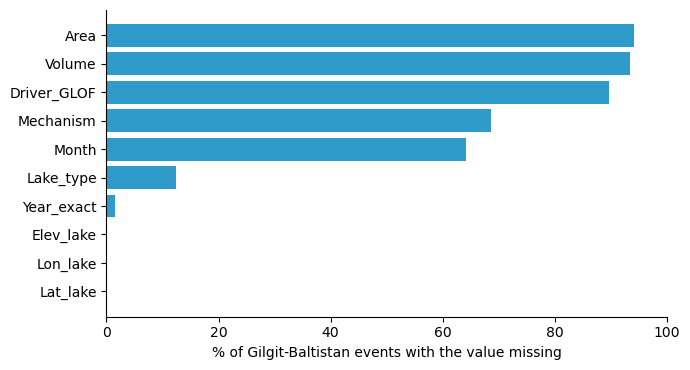

In [46]:
key_cols = ['Year_exact', 'Month', 'Lat_lake', 'Lon_lake', 'Elev_lake', 'Lake_type', 'Driver_GLOF', 'Mechanism', 'Area', 'Volume']
missing = (gb_df[key_cols].isna().mean() * 100).sort_values()
print((missing.round(0).astype(int).astype(str) + '% missing').to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(missing.index, missing.values, color=BLUE)
ax.set_xlabel('% of Gilgit-Baltistan events with the value missing'); ax.set_xlim(0, 100)
plt.tight_layout(); plt.savefig('figures/missing_data.png', dpi=200); plt.show()

Events with a known year: 135 of 137 | earliest: 1661 | latest: 2022
Events before 1900: 22


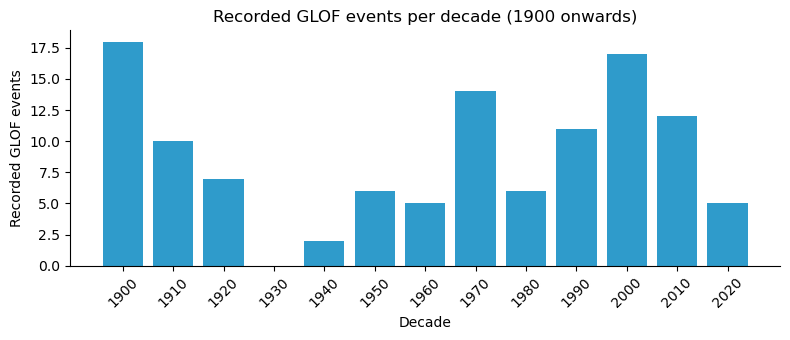

In [47]:
years = gb_df['Year_exact'].dropna()
print('Events with a known year:', len(years), 'of', len(gb_df), '| earliest:', int(years.min()), '| latest:', int(years.max()))
print('Events before 1900:', int((years < 1900).sum()))

decade = (years // 10 * 10).astype(int)
dec_counts = decade[decade >= 1900].value_counts().reindex(range(1900, 2030, 10), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(dec_counts.index.astype(str), dec_counts.values, color=BLUE)
ax.set_xlabel('Decade'); ax.set_ylabel('Recorded GLOF events')
ax.set_title('Recorded GLOF events per decade (1900 onwards)')
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig('figures/events_per_decade.png', dpi=200); plt.show()

Events with a known month: 49 of 137


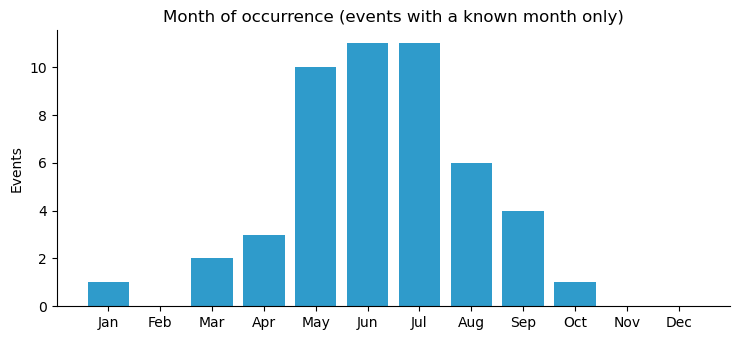

May-July: 32 of 49 events with a known month


In [48]:
months = gb_df['Month'].dropna().astype(int)
print('Events with a known month:', len(months), 'of', len(gb_df))
mcounts = months.value_counts().reindex(range(1, 13), fill_value=0)
names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(names, mcounts.values, color=BLUE)
ax.set_ylabel('Events'); ax.set_title('Month of occurrence (events with a known month only)')
plt.tight_layout(); plt.savefig('figures/events_by_month.png', dpi=200); plt.show()
print('May-July:', int(mcounts[[5,6,7]].sum()), 'of', int(mcounts.sum()), 'events with a known month')

### What kind of lakes, what triggered the floods?

Lake_type
Ice dammed          76
Supraglacial        26
Unknown             17
Moraine dammed      14
Landslide dammed     3
Water pocket         1

Driver_GLOF
Unknown              123
Intense rainfall       8
High temperatures      5
Rockfall               1


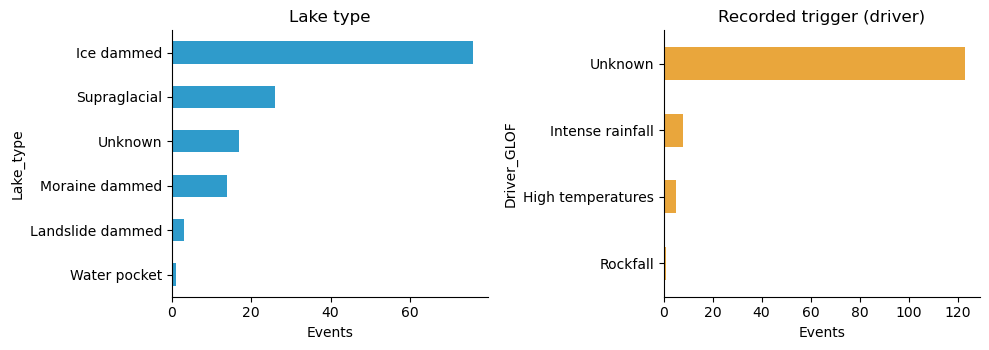

In [49]:
lake = gb_df['Lake_type'].fillna('Unknown').value_counts()
driver = gb_df['Driver_GLOF'].fillna('Unknown').value_counts()
print(lake.to_string()); print(); print(driver.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
lake.sort_values().plot.barh(ax=axes[0], color=BLUE); axes[0].set_title('Lake type'); axes[0].set_xlabel('Events')
driver.sort_values().plot.barh(ax=axes[1], color=ORANGE); axes[1].set_title('Recorded trigger (driver)'); axes[1].set_xlabel('Events')
plt.tight_layout(); plt.savefig('figures/lake_type_and_driver.png', dpi=200); plt.show()

### 2.4 What impacts were recorded?

Injured_total             0
Residential_damaged       0
Commerical_damaged        0
Hydropower                0
Displaced_total           1
Livestock                 1
Econ_damage               1
Impact                    2
Commerical_destroyed      3
Lives_total               4
Agricultural             18
Residential_destroyed    27
Infra                    36


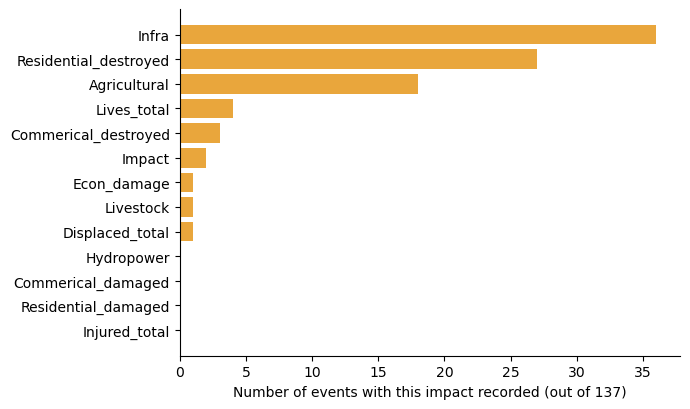

In [50]:
impact_cols = ['Lives_total','Injured_total','Displaced_total','Impact','Livestock',
               'Residential_destroyed','Residential_damaged','Commerical_destroyed',
               'Commerical_damaged','Infra','Agricultural','Econ_damage','Hydropower']
impact_cols = [c for c in impact_cols if c in gb_df.columns]
counts = gb_df[impact_cols].notna().sum().sort_values()
print(counts.to_string())

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(counts.index, counts.values, color=ORANGE)
ax.set_xlabel('Number of events with this impact recorded (out of %d)' % len(gb_df))
plt.tight_layout(); plt.savefig('figures/impact_types.png', dpi=200); plt.show()

## Target and features if the database records impact for the event ,otherwise 0 which means no impact recored

In [51]:
gb_df['AnyImpact'] = gb_df[impact_cols].notna().any(axis=1).astype(int)

useful = ['Year_exact', 'Lake_type', 'Driver_GLOF', 'Lat_lake', 'Lon_lake', 'AnyImpact']
df_model = gb_df[useful].copy()
df_model['Year_exact'] = df_model['Year_exact'].fillna(df_model['Year_exact'].median())  # only 2 missing
for col in ['Lake_type', 'Driver_GLOF']:
    df_model[col] = df_model[col].fillna('Unknown')
    df_model[col + '_encoded'] = LabelEncoder().fit_transform(df_model[col])

print(df_model['AnyImpact'].value_counts().rename({0: 'No impact recorded', 1: 'Impact recorded'}).to_string())

feature_cols = ['Lake_type_encoded', 'Driver_GLOF_encoded', 'Year_exact', 'Lat_lake', 'Lon_lake']
X, y = df_model[feature_cols], df_model['AnyImpact']
baseline = max(y.mean(), 1 - y.mean())
print('\nMajority-class baseline (always guess the more common answer): %.1f%%' % (baseline * 100))

AnyImpact
No impact recorded    76
Impact recorded       61

Majority-class baseline (always guess the more common answer): 55.5%


###  Where are the events, and where did they have recorded impact?

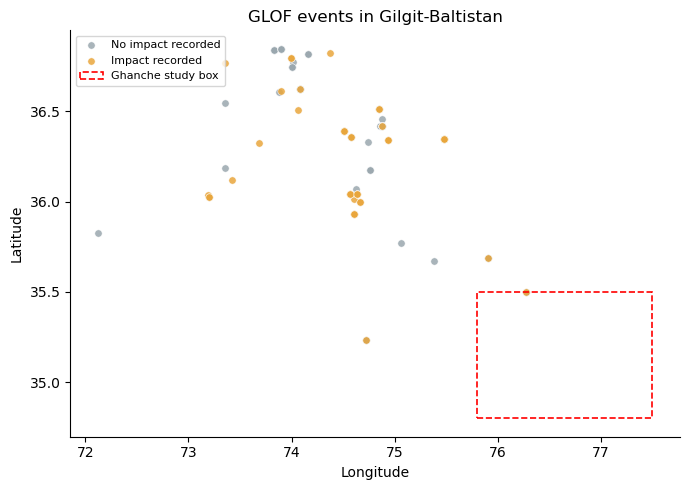

In [52]:
fig, ax = plt.subplots(figsize=(7, 5))
for val, col, lab in [(0, GREY, 'No impact recorded'), (1, ORANGE, 'Impact recorded')]:
    s = gb_df[gb_df['AnyImpact'] == val]
    ax.scatter(s['Lon_lake'], s['Lat_lake'], c=col, label=lab, s=28, alpha=.85, edgecolors='white', linewidths=.4)
ax.add_patch(Rectangle((75.8, 34.8), 77.5 - 75.8, 35.5 - 34.8, fill=False, ls='--', ec='red', lw=1.2, label='Ghanche study box'))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('GLOF events in Gilgit-Baltistan')
plt.tight_layout(); plt.savefig('figures/event_map.png', dpi=200); plt.show()

Note: the three events inside the Ghanche box (all from the Hushe basin) share the same coordinates, so they appear as one dot on the map they are basically three stack on each other

### 3.2 A warning sign: do recorded impacts depend on the period?

Year_exact
before 1900    35%  (n=23)
1900-49        36%  (n=36)
1950-79        64%  (n=28)
1980-99        44%  (n=18)
2000+          43%  (n=30)
dtype: object


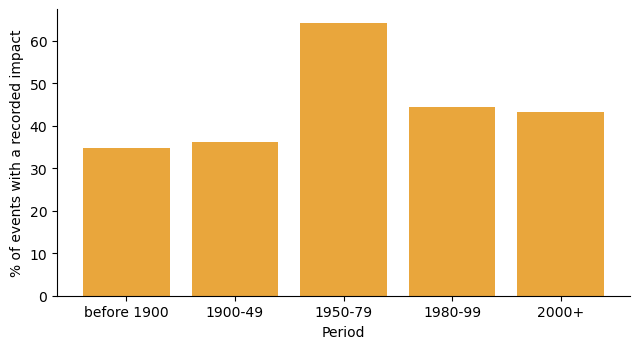

In [53]:
periods = pd.cut(gb_df['Year_exact'], [0, 1900, 1950, 1980, 2000, 2030],
                 labels=['before 1900', '1900-49', '1950-79', '1980-99', '2000+'])
share = gb_df.groupby(periods)['AnyImpact'].agg(['mean', 'count'])
print((share['mean'] * 100).round(0).astype(int).astype(str) + '%  (n=' + share['count'].astype(str) + ')')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(share.index.astype(str), share['mean'] * 100, color=ORANGE)
ax.set_ylabel('% of events with a recorded impact'); ax.set_xlabel('Period')
plt.tight_layout(); plt.savefig('figures/impact_by_period.png', dpi=200); plt.show()

## Models and honest testing Four models are compared: Random Forest, Gradient Boosting, Decision Tree and Logistic Regression.


Random Forest          LOOCV accuracy 69.3%   F1 0.632
Gradient Boosting      LOOCV accuracy 70.1%   F1 0.637
Decision Tree          LOOCV accuracy 69.3%   F1 0.632
Logistic Regression    LOOCV accuracy 59.9%   F1 0.466

Majority-class baseline: 55.5%


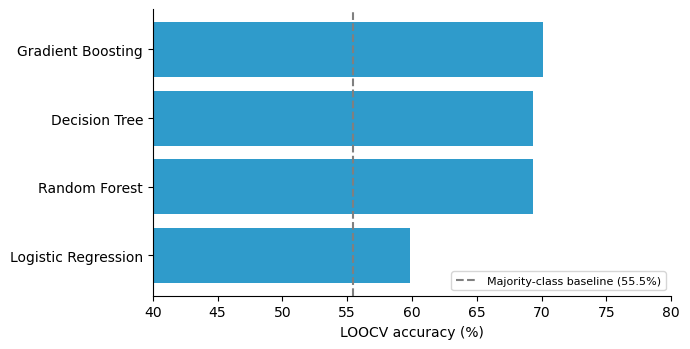

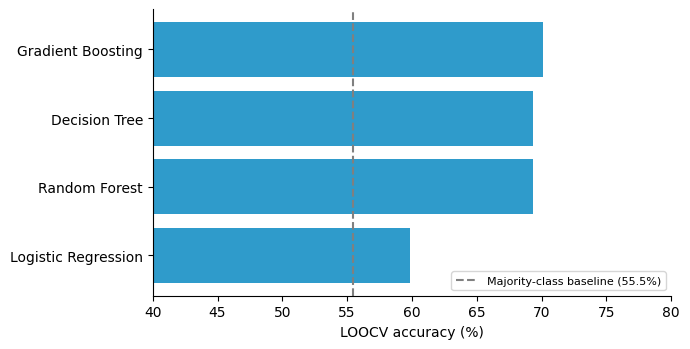

In [54]:
models = {
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(max_depth=8, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
}

results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), clone(model))
    pred = cross_val_predict(pipe, X, y, cv=LeaveOneOut())
    results[name] = {'acc': accuracy_score(y, pred), 'f1': f1_score(y, pred), 'pred': pred}
    print(f"{name:<22} LOOCV accuracy {results[name]['acc']*100:.1f}%   F1 {results[name]['f1']:.3f}")
print(f"\nMajority-class baseline: {baseline*100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.6))
order = sorted(results, key=lambda k: results[k]['acc'])
ax.barh(order, [results[k]['acc'] * 100 for k in order], color=BLUE)
ax.axvline(baseline * 100, color='grey', ls='--', label='Majority-class baseline (%.1f%%)' % (baseline * 100))
ax.set_xlabel('LOOCV accuracy (%)'); ax.set_xlim(40, 80); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('figures/model_comparison.png', dpi=200); plt.show()

### 4.1 Where does the best model go wrong?

Best model: Gradient Boosting
                    precision    recall  f1-score   support

No impact recorded       0.71      0.79      0.75        76
   Impact recorded       0.69      0.59      0.64        61

          accuracy                           0.70       137
         macro avg       0.70      0.69      0.69       137
      weighted avg       0.70      0.70      0.70       137



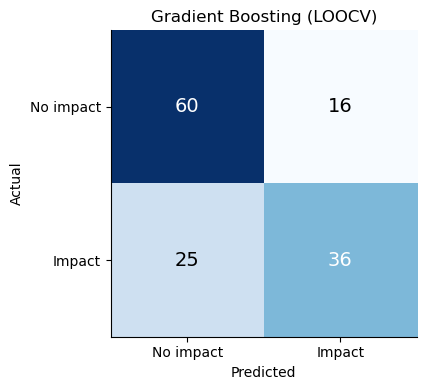

In [55]:
best = max(results, key=lambda k: results[k]['acc'])
cm = confusion_matrix(y, results[best]['pred'])
print('Best model:', best)
print(classification_report(y, results[best]['pred'], target_names=['No impact recorded', 'Impact recorded']))

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['No impact', 'Impact']); ax.set_yticklabels(['No impact', 'Impact'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(best + ' (LOOCV)')
plt.tight_layout(); plt.savefig('figures/confusion_matrix.png', dpi=200); plt.show()

## 5. How reliable are these results?

### 5.1 A single train/test split can be misleading
A common way to test is one 80/20 split. Here the test set has only 28 events, so the result depends heavily on which events land in it. The next cell repeats the split 200 times.

Gradient Boosting, 200 random 80/20 splits:
  mean 69.5% | min 50.0% | max 89.3%
  share of splits reaching 85.7% or more: 4.0%


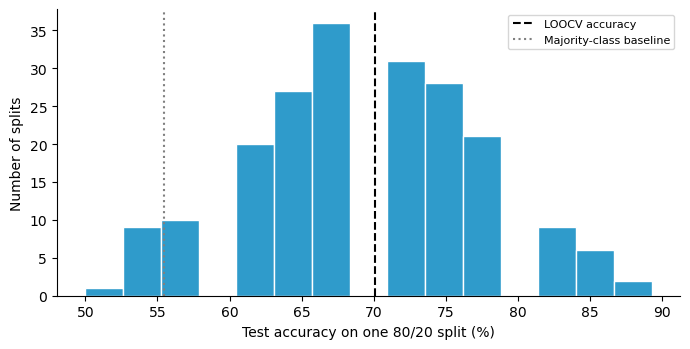

In [56]:
accs = []
for seed in range(200):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    m = GradientBoostingClassifier(n_estimators=100, random_state=seed).fit(Xa, ya)
    accs.append(accuracy_score(yb, m.predict(Xb)))
accs = np.array(accs)
print('Gradient Boosting, 200 random 80/20 splits:')
print('  mean %.1f%% | min %.1f%% | max %.1f%%' % (accs.mean()*100, accs.min()*100, accs.max()*100))
print('  share of splits reaching 85.7%% or more: %.1f%%' % ((accs >= 0.857).mean() * 100))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(accs * 100, bins=15, color=BLUE, edgecolor='white')
ax.axvline(results['Gradient Boosting']['acc'] * 100, color='black', ls='--', label='LOOCV accuracy')
ax.axvline(baseline * 100, color='grey', ls=':', label='Majority-class baseline')
ax.set_xlabel('Test accuracy on one 80/20 split (%)'); ax.set_ylabel('Number of splits'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/split_instability.png', dpi=200); plt.show()

A single lucky split can look much better than the real performance. **Report the cross-validated numbers**, not the best single split.

### 5.2 What is the model actually using?
This test removes features one group at a time and checks the LOOCV accuracy again. If the score barely drops, the removed feature wasn't helping.

                     Random Forest  Gradient Boosting
All 5 features                69.3               70.1
No trigger (driver)           69.3               71.5
No year                       65.7               66.4
Year + location               68.6               70.8
Location only                 65.0               67.2


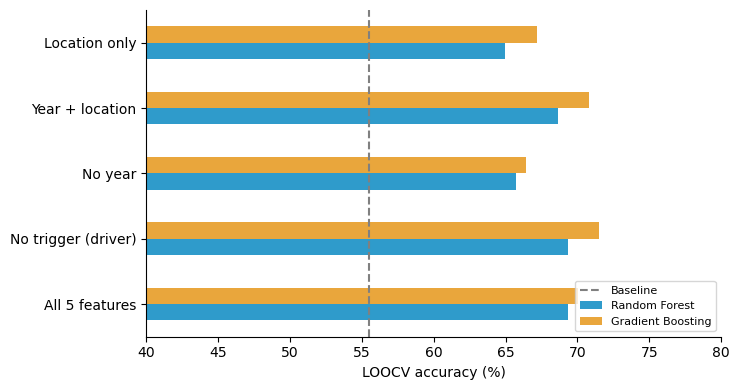

In [57]:
sets = {
    'All 5 features':        ['Lake_type_encoded', 'Driver_GLOF_encoded', 'Year_exact', 'Lat_lake', 'Lon_lake'],
    'No trigger (driver)':   ['Lake_type_encoded', 'Year_exact', 'Lat_lake', 'Lon_lake'],
    'No year':               ['Lake_type_encoded', 'Driver_GLOF_encoded', 'Lat_lake', 'Lon_lake'],
    'Year + location':       ['Year_exact', 'Lat_lake', 'Lon_lake'],
    'Location only':         ['Lat_lake', 'Lon_lake'],
}
ab = {}
for label, cols in sets.items():
    ab[label] = {}
    for n in ['Random Forest', 'Gradient Boosting']:
        p = cross_val_predict(clone(models[n]), df_model[cols], y, cv=LeaveOneOut())
        ab[label][n] = accuracy_score(y, p) * 100
ab = pd.DataFrame(ab).T
print(ab.round(1).to_string())

ax = ab.plot.barh(figsize=(7.5, 4), color=[BLUE, ORANGE])
ax.axvline(baseline * 100, color='grey', ls='--', label='Baseline')
ax.set_xlabel('LOOCV accuracy (%)'); ax.set_xlim(40, 80); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig('figures/feature_ablation.png', dpi=200); plt.show()

## 6. The Ghanche area

A rough rectangle around Ghanche (latitude 34.8 to 35.5, longitude 75.8 to 77.5) is used. It is **not** the exact district border.

In [58]:
gh = gb_df[(gb_df['Lat_lake'] >= 34.8) & (gb_df['Lat_lake'] <= 35.5) &
           (gb_df['Lon_lake'] >= 75.8) & (gb_df['Lon_lake'] <= 77.5)]
print('Events in the Ghanche study box:', len(gh))
print(gh[['Year_exact', 'Lake_type', 'Driver_GLOF', 'River_Basin', 'AnyImpact']].to_string())

Events in the Ghanche study box: 3
     Year_exact       Lake_type Driver_GLOF River_Basin  AnyImpact
342      1990.0  Moraine dammed    Rockfall       Hushe          1
358      1993.0  Moraine dammed         NaN       Hushe          0
389      2000.0  Moraine dammed         NaN       Hushe          0


With so few events, no model can say anything reliable about one valley. This table can only be used as a **case description**, not as a prediction for any village.

## 7. Summary

In [59]:
print('SUMMARY')
print('-' * 60)
print('Events in database:                 ', len(df))
print('Events in Gilgit-Baltistan:         ', len(gb_df))
print('Events with a recorded impact:      ', int(y.sum()), '(%.0f%%)' % (y.mean() * 100))
print('Majority-class baseline:             %.1f%%' % (baseline * 100))
for k in sorted(results, key=lambda k: -results[k]['acc']):
    print('  %-20s LOOCV accuracy %.1f%%' % (k, results[k]['acc'] * 100))
print('Single 80/20 split (Gradient Boosting): mean %.1f%%, range %.0f%% to %.0f%%' % (accs.mean()*100, accs.min()*100, accs.max()*100))
print('Location-only (Random Forest):       %.1f%%' % ab.loc['Location only', 'Random Forest'])

SUMMARY
------------------------------------------------------------
Events in database:                  703
Events in Gilgit-Baltistan:          137
Events with a recorded impact:       61 (45%)
Majority-class baseline:             55.5%
  Gradient Boosting    LOOCV accuracy 70.1%
  Random Forest        LOOCV accuracy 69.3%
  Decision Tree        LOOCV accuracy 69.3%
  Logistic Regression  LOOCV accuracy 59.9%
Single 80/20 split (Gradient Boosting): mean 69.5%, range 50% to 89%
Location-only (Random Forest):       65.0%
